Load the digits dataset, make a stratified split, and scale using training data only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
print("Training tensor shape:", tuple(X_train_tensor.shape))
print("Test tensor shape:", tuple(X_test_tensor.shape))

Training tensor shape: (1437, 64)
Test tensor shape: (360, 64)


Train the specified neural network for 50 epochs and record training loss and test accuracy.

In [2]:
def build_model():
    return nn.Sequential(
        nn.Linear(64, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    )

def train_model(learning_rate, epochs=50):
    torch.manual_seed(42)
    model = build_model()
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loader = DataLoader(train_dataset, batch_size=len(train_dataset), shuffle=True)
    train_losses = []
    test_accuracies = []

    for epoch in range(epochs):
        model.train()
        for batch_features, batch_labels in loader:
            logits = model(batch_features)
            loss = loss_function(logits, batch_labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        train_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            test_logits = model(X_test_tensor)
            test_predictions = test_logits.argmax(dim=1)
            test_accuracy = (test_predictions == y_test_tensor).float().mean().item()
        test_accuracies.append(test_accuracy)

    return model, train_losses, test_accuracies

model, train_losses, test_accuracies = train_model(learning_rate=1e-3)
print(f"Final test accuracy at lr=1e-3: {test_accuracies[-1]:.4f}")

Final test accuracy at lr=1e-3: 0.8944


Plot training loss and test accuracy over the 50 training epochs.

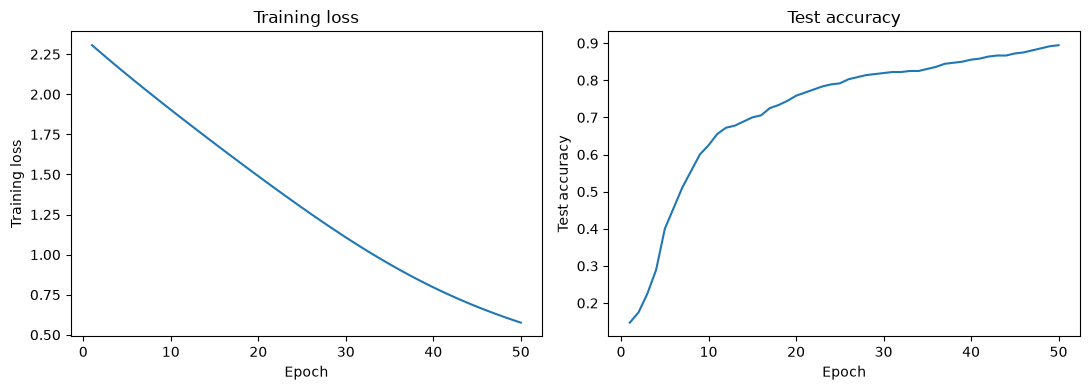

In [3]:
epochs = np.arange(1, len(train_losses) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, train_losses)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training loss")
axes[0].set_title("Training loss")
axes[1].plot(epochs, test_accuracies)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Test accuracy")
axes[1].set_title("Test accuracy")
fig.tight_layout()
plt.show()

Train one model per learning rate, plot their loss curves, and compare final accuracy with Day 4 logistic regression.

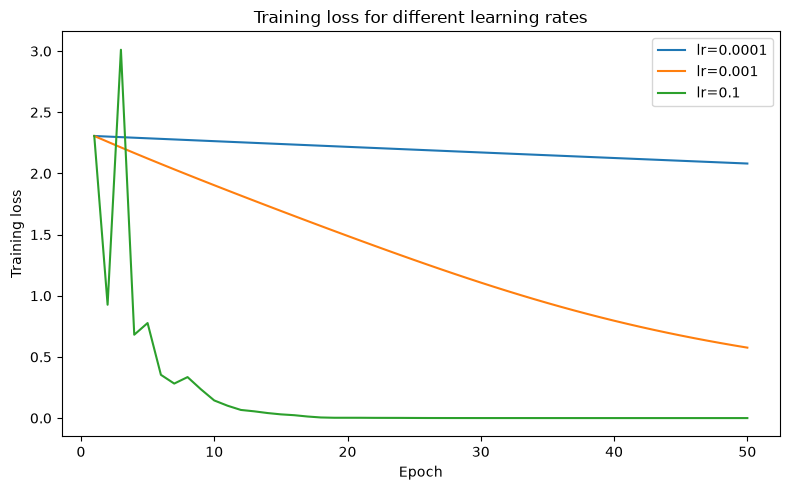

Learning rate Final test accuracy
       0.0001              0.3889
        0.001              0.8944
          0.1              0.9639
Day 4 logistic regression test accuracy: 0.9583
lr=0.0001: difference vs logistic regression = -0.5694
lr=0.001: difference vs logistic regression = -0.0639
lr=0.1: difference vs logistic regression = +0.0056


In [4]:
learning_rates = [1e-4, 1e-3, 1e-1]
lr_results = {}
for learning_rate in learning_rates:
    _, losses, accuracies = train_model(learning_rate=learning_rate)
    lr_results[learning_rate] = {"losses": losses, "test_accuracy": accuracies[-1]}

plt.figure(figsize=(8, 5))
for learning_rate, result in lr_results.items():
    plt.plot(np.arange(1, 51), result["losses"], label=f"lr={learning_rate:g}")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training loss for different learning rates")
plt.legend()
plt.tight_layout()
plt.show()

lr_accuracy = pd.DataFrame([
    {"Learning rate": learning_rate, "Final test accuracy": result["test_accuracy"]}
    for learning_rate, result in lr_results.items()
])
print(lr_accuracy.to_string(index=False, formatters={
    "Learning rate": "{:.4g}".format,
    "Final test accuracy": "{:.4f}".format,
}))
day4_logistic_accuracy = 0.9583
print(f"Day 4 logistic regression test accuracy: {day4_logistic_accuracy:.4f}")
for learning_rate, result in lr_results.items():
    difference = result["test_accuracy"] - day4_logistic_accuracy
    print(f"lr={learning_rate:g}: difference vs logistic regression = {difference:+.4f}")

Count and print the trainable parameters in the neural network.

In [5]:
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print("Total trainable parameters:", trainable_parameters)

Total trainable parameters: 9610
